# КТ2 — AI-диспетчер критических инцидентов

Сообщения об инцидентах приходят из производства, ИТ, ритейла и логистики, и пишут их все по-разному. Диспетчер читает каждое, решает, насколько все плохо, кому отдать и что делать первым. На это уходит время, и опасный случай легко потерять среди «срочных» мелочей.

**Что делает система.** Language-модель читает сообщение и готовит карточку: критичность, владелец, первый безопасный шаг, цитата-доказательство, что неизвестно и нужен ли человек.
**Цена ошибок.** Самое дорогое — занизить критичность опасного случая или отдать его не тому владельцу: простой, ущерб, взлом. Завысить мелочь тоже плохо: дежурный бросает настоящую аварию ради «срочно» от одного пользователя. И отдельный риск — модель уверенно выдумывает детали, которых в сообщении не было, а диспетчер ей верит.

Задача: сравнить три версии инструкции (A — короткая, B — структура, C — управляемый AI) на 30 обязательных случаях и понять, какую версию можно пускать в работу и в каком режиме.

**Для Colab.** Ollama и Rust в Colab не запускаю, поэтому ноутбук берет готовые результаты. Загрузить в ячейке ниже:
- `КТ2_отчёты_об_инцидентах.csv`, `llm_raw.jsonl`, `rust_journal.csv`, `rust_summary.csv`, `rust_compare.csv`, `rust_sim.csv`, `допущения_времени.csv` (все из папки `data/`);
- `A_короткая.txt`, `B_структура.txt`, `C_управляемый_AI.txt` (из папки `инструкции/`).

In [ ]:
import os
for folder in ['data', 'img', 'инструкции']:
    os.makedirs(folder, exist_ok=True)
try:
    from google.colab import files
    up = files.upload()
    for name, blob in up.items():
        folder = 'инструкции' if name.endswith('.txt') else 'data'
        with open(os.path.join(folder, name), 'wb') as f:
            f.write(blob)
    print('загружено:', ', '.join(up))
except ImportError:
    print('запущено не в Colab, файлы уже на месте')

In [1]:
import hashlib
import json
import os
import shutil
import subprocess
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

DATA = Path('data')
incidents = pd.read_csv(DATA / 'КТ2_отчёты_об_инцидентах.csv')
cases = incidents[incidents.mandatory == 'да'].reset_index(drop=True)

print('сообщений всего:', len(incidents), '| обязательных:', len(cases), '| резерв:', (incidents.mandatory == 'резерв').sum())
print('уникальных текстов среди 30:', cases.report_text.nunique())
display(cases.head(6))
display(pd.crosstab(cases.gold_severity, cases.gold_human_review, margins=True, margins_name='всего'))

сообщений всего: 36 | обязательных: 30 | резерв: 6
уникальных текстов среди 30: 9


,incident_id,mandatory,industry,report_text,gold_severity,gold_owner,gold_first_action,gold_human_review
0,INC-001,да,производство,После обновления перестал отвечать основной се...,Критический,дежурный инженер,остановить затронутый контур и проверить резерв,нет
1,INC-002,да,ИТ,На линии растёт вибрация и температура подшипн...,Высокий,начальник смены,снизить скорость линии и проверить узел,нет
2,INC-003,да,ритейл,"Часть терминалов не синхронизирует остатки, от...",Средний,руководитель склада,проверить сканеры и назначить ручной обход,нет
3,INC-004,да,логистика,Один пользователь сообщает о медленном открыти...,Низкий,сервис-менеджер,уточнить масштаб и собрать логи,да
4,INC-005,да,финансы,Обнаружены входы из необычной страны и серия н...,Высокий,служба информационной безопасности,изолировать учётную запись и проверить события,нет
5,INC-006,да,телеком,Несколько машин задерживаются из-за перекрытия...,Средний,диспетчер логистики,проверить маршрут и предупредить клиентов,нет


gold_human_review,да,нет,всего
gold_severity,,,
Высокий,2,8,10
Критический,0,5,5
Низкий,3,2,5
Средний,2,8,10
всего,7,23,30


In [2]:
URGENT = 'Автор пишет: «срочно»'
cases['urgent'] = cases.report_text.str.contains(URGENT, regex=False)
cases['base_text'] = cases.report_text.str.replace(r'\s*Автор пишет:.*$', '', regex=True)

templates = (cases.groupby('base_text', sort=False)
             .agg(отрасль=('industry', 'first'), случаев=('incident_id', 'size'), со_срочно=('urgent', 'sum'),
                  severity=('gold_severity', 'first'), owner=('gold_owner', 'first'), first_action=('gold_first_action', 'first'))
             .reset_index())
templates.index = [f'T{i}' for i in range(1, len(templates) + 1)]
cases['template'] = cases.base_text.map(dict(zip(templates.base_text, templates.index)))
display(templates)
print('цифр во всех текстах сообщений:', int(cases.report_text.str.count(r'\d').sum()))

,base_text,отрасль,случаев,со_срочно,severity,owner,first_action
T1,После обновления перестал отвечать основной се...,производство,5,0,Критический,дежурный инженер,остановить затронутый контур и проверить резерв
T2,На линии растёт вибрация и температура подшипн...,ИТ,5,2,Высокий,начальник смены,снизить скорость линии и проверить узел
T3,"Часть терминалов не синхронизирует остатки, от...",ритейл,5,0,Средний,руководитель склада,проверить сканеры и назначить ручной обход
T4,Один пользователь сообщает о медленном открыти...,логистика,5,3,Низкий,сервис-менеджер,уточнить масштаб и собрать логи
T5,Обнаружены входы из необычной страны и серия н...,финансы,5,0,Высокий,служба информационной безопасности,изолировать учётную запись и проверить события
T6,Несколько машин задерживаются из-за перекрытия...,телеком,5,2,Средний,диспетчер логистики,проверить маршрут и предупредить клиентов


цифр во всех текстах сообщений: 0


Что видно сразу:
1. 30 случаев — это **6 шаблонов по 5 раз**, уникальных текстов всего 9 (у трех шаблонов есть вариант с припиской про «срочно»). Значит, эксперимент заодно проверяет стабильность: один и тот же текст должен получать один и тот же ответ.
2. Приписка «Автор пишет: «срочно», но число затронутых объектов не указано» есть в 7 случаях. Эталонная критичность от нее **не меняется** (низкий так и остается низким), меняется только human_review: нужен человек. Это ловушка на неверную срочность.
3. Поле `industry` местами не совпадает с текстом: вибрация подшипника пришла из «ИТ», задержка машин — из «телеком». Эталонный владелец везде выбран по тексту, а не по отрасли. Это источник неоднозначности.
4. В текстах нет ни одной цифры. Если модель пишет число затронутых клиентов или время — это выдумка.
5. Резервные 6 случаев — те же шаблоны, в эксперимент их не брал.

## Шаги 1–3. Три версии инструкции

Все три версии получают на вход одно и то же: отрасль и текст сообщения. Меняется только инструкция.

- **A — короткая.** Ровно как в задании: «Определи критичность и действие». Ответ сохраняю как есть, без улучшений.
- **B — структура.** Те же 6 полей, что в задании: severity, owner, first_action, evidence_quote, unknowns, human_review. Шкалу критичности задал списком, иначе модель пишет что угодно. Больше ничего не подсказываю.
- **C — управляемый AI.** Добавил:
  1. правила критичности по влиянию и масштабу, а не по тону («срочно» критичность не повышает);
  2. справочник владельцев компании: без него модель просто не знает наших ролей;
  3. правило, что поле «Отрасль» — это канал, а не суть;
  4. запрет на выдумывание: цитата дословно, все, чего нет в тексте, идет в unknowns;
  5. обязательную эскалацию (human_review = да), если просят срочно без масштаба, не хватает данных или есть противоречие;
  6. три примера. **Примеры специально придумал свои, не из 30 случаев.** Если взять примеры из датасета, модель просто перепишет готовый ответ и C будет выглядеть лучше, чем есть.
  7. поле facts и порядок полей «факты → цитата → неизвестное → выводы»: пусть модель сначала выпишет, что есть в тексте, а потом решает.

Сами инструкции лежат в папке `инструкции/`, ячейка ниже читает их оттуда.

In [3]:
PROMPTS = {unicodedata.normalize('NFC', p.stem): p.read_text(encoding='utf-8')
           for p in sorted(Path('инструкции').glob('*.txt'))}
for name, text in PROMPTS.items():
    print(f'{name}: {len(text)} символов')
print('\n--- A ---\n' + PROMPTS['A_короткая'])
print('--- B ---\n' + PROMPTS['B_структура'])

A_короткая: 79 символов
B_структура: 427 символов
C_управляемый_AI: 4362 символов

--- A ---
Определи критичность и действие.

Отрасль: {industry}
Сообщение: {report_text}

--- B ---
Разбери сообщение об инциденте. Ответь только JSON-объектом с полями:
"severity" — критичность: "Критический", "Высокий", "Средний" или "Низкий";
"owner" — кто отвечает за инцидент;
"first_action" — первый шаг;
"evidence_quote" — цитата из сообщения, на которой основан вывод;
"unknowns" — список того, что неизвестно;
"human_review" — нужна ли проверка человеком: "да" или "нет".

Отрасль: {industry}
Сообщение: {report_text}



## Прогон: 30 случаев × 3 версии

Основная модель — **qwen2.5:7b** локально через Ollama, для проверки те же запросы идут в **llama3** (8B). Почему локально: в сообщениях бывают инциденты информационной безопасности, отправлять такое во внешний чат нельзя. Плюс так эксперимент можно повторить один в один.

Как запускаю:
- температура и остальное — настройки модели по умолчанию, как в обычном чате;
- seed = номер случая, одинаковый для A, B и C. Так у версий одинаковые условия, а одинаковые тексты внутри версии получают разный seed, и видно, насколько ответ гуляет;
- сначала все A, потом все B, потом все C: Ollama переиспользует уже посчитанный префикс промпта, выходит быстрее;
- каждый ответ сразу пишется в `data/llm_raw.jsonl`. Если ответ уже есть, второй раз модель не спрашиваю. Без Ollama ноутбук просто берет ответы из этого файла.

Пробный прогон я делал на ноутбуке (Intel i9, только CPU): один ответ версии A шел от 1 до 4,5 минут, все 180 ответов заняли бы часов пять. Поэтому основной прогон сделал на домашнем компьютере с видеокартой RTX 5080: в среднем 1–3 секунды на ответ, обе модели по 90 ответов — около 11 минут. Ответы пробного прогона удалил, чтобы все 180 были получены в одинаковых условиях. Прогон можно прервать в любой момент: уже полученные ответы лежат в кэше, при следующем запуске модель спрашивается только про недостающие.

In [4]:
MODEL = 'qwen2.5:7b'
SECOND = 'llama3:latest'
OLLAMA = 'http://localhost:11434'
RAW = DATA / 'llm_raw.jsonl'
OPTIONS = {'num_ctx': 4096, 'num_predict': 700}


def prompt_sha(template):
    return hashlib.sha1(template.encode('utf-8')).hexdigest()[:10]


def load_raw(path=RAW):
    if not path.exists():
        return pd.DataFrame(columns=['incident_id', 'prompt_version', 'model', 'prompt_sha', 'response'])
    lines = path.read_text(encoding='utf-8').splitlines()
    return pd.DataFrame([json.loads(line) for line in lines if line.strip()])


def ollama_alive():
    try:
        return requests.get(f'{OLLAMA}/api/version', timeout=3).ok
    except requests.RequestException:
        return False


def ask(model, prompt, seed):
    body = {'model': model, 'messages': [{'role': 'user', 'content': prompt}], 'stream': False,
            'keep_alive': '1h', 'options': {**OPTIONS, 'seed': seed}}
    r = requests.post(f'{OLLAMA}/api/chat', json=body, timeout=1800)
    r.raise_for_status()
    return r.json()


def run_experiment(model, cases, prompts):
    raw = load_raw()
    done = set(zip(raw.model, raw.prompt_version, raw.incident_id, raw.prompt_sha))
    todo = [(v, c) for v in prompts for c in cases.itertuples()
            if (model, v, c.incident_id, prompt_sha(prompts[v])) not in done]
    if not todo:
        print(f'{model}: все {len(cases) * len(prompts)} ответов уже в кэше')
        return
    if not ollama_alive():
        print(f'Ollama не отвечает, а в кэше не хватает {len(todo)} ответов')
        return
    t0 = time.time()
    for i, (v, c) in enumerate(todo, 1):
        prompt = prompts[v].replace('{industry}', c.industry).replace('{report_text}', c.report_text)
        seed = int(c.incident_id.split('-')[1])
        res = ask(model, prompt, seed)
        rec = {'incident_id': c.incident_id, 'prompt_version': v, 'model': model, 'prompt_sha': prompt_sha(prompts[v]),
               'seed': seed, 'response': res['message']['content'], 'prompt_tokens': res.get('prompt_eval_count'),
               'output_tokens': res.get('eval_count'), 'seconds': round(res.get('total_duration', 0) / 1e9, 2)}
        with RAW.open('a', encoding='utf-8') as f:
            f.write(json.dumps(rec, ensure_ascii=False) + '\n')
        if i % 10 == 0 or i == len(todo):
            print(f'  {model}: {i}/{len(todo)}, прошло {(time.time() - t0) / 60:.1f} мин')


if ollama_alive():
    info = requests.post(f'{OLLAMA}/api/show', json={'model': MODEL}, timeout=30).json()
    print(MODEL, '|', info['details']['parameter_size'], info['details']['quantization_level'])
    params = ' '.join(info.get('parameters', '').split())
    print('настройки модели:', params or 'свои не заданы, работают стандартные Ollama (temperature 0.8, top_p 0.9, top_k 40)')
for m in (MODEL, SECOND):
    run_experiment(m, cases, PROMPTS)

raw = load_raw()
main_raw = raw[raw.model == MODEL]
print(f'\nответов {MODEL}: {len(main_raw)}')
display(main_raw.groupby('prompt_version')[['prompt_tokens', 'output_tokens', 'seconds']].mean().round(1))

qwen2.5:7b | 7.6B Q4_K_M
настройки модели: свои не заданы, работают стандартные Ollama (temperature 0.8, top_p 0.9, top_k 40)
qwen2.5:7b: все 90 ответов уже в кэше
llama3:latest: все 90 ответов уже в кэше

ответов qwen2.5:7b: 90


,prompt_tokens,output_tokens,seconds
prompt_version,,,
A_короткая,84.9,430.9,3.1
B_структура,205.9,126.4,0.9
C_управляемый_AI,1552.9,151.9,1.0


In [5]:
def show_answers(incident_id, model=MODEL):
    row = cases.set_index('incident_id').loc[incident_id]
    print(f'{incident_id} [{row.industry}] {row.report_text}')
    print(f'эталон: {row.gold_severity} | {row.gold_owner} | {row.gold_first_action} | human_review={row.gold_human_review}\n')
    for v in PROMPTS:
        r = raw[(raw.model == model) & (raw.incident_id == incident_id) & (raw.prompt_version == v)]
        if len(r):
            print(f'===== {v}\n{r.response.iloc[0].strip()}\n')


show_answers('INC-004')

INC-004 [логистика] Один пользователь сообщает о медленном открытии отчёта, повторить пока не удалось. Автор пишет: «срочно», но число затронутых объектов не указано.
эталон: Низкий | сервис-менеджер | уточнить масштаб и собрать логи | human_review=да

===== A_короткая
Критичность: Средняя

Действие:

1. Связаться с пользователем и уточнить информацию о том, сколько пользователей столкнулись с данной проблемой и как часто это происходит.

2. Проверить серверные ресурсы и загрузку системы, чтобы выяснить, не связана ли медленная загрузка с техническими ограничениями или перегрузкой системы.

3. Проверить состояние клиентского приложения или браузера, на случай, если проблема связана с техническими проблемами на стороне клиента.

4. Если проблема повторяется, следует провести более подробное тестирование и логирование приложения, чтобы выяснить причину задержек.

5. Обратить внимание на производительность системы и возможные проблемы с базой данных, если они могут влиять на скорость откр

## Шаг 4. Проверка 30 случаев

### Как я проверяю ответы

Проверять 90 ответов только глазами долго и субъективно, поэтому сделал в два слоя: сначала правила, потом ручная проверка.

1. **Разбор ответа.** У B и C это JSON. У A свободный текст, поэтому критичность, первый шаг и адресата вытаскиваю правилами: что написано после «Критичность:», «Действие:» и т. п.
2. **Оценка по эталону.** Критичность — точное совпадение. Владелец — по словарю ролей из `data/рубрика.csv`: например, «ИТ-отдел» для дежурного инженера — да, «техподдержка» — частично. Первый шаг — по смысловым частям эталона: «остановить контур **и** проверить резерв», обе части есть — да, одна — частично.
3. **Цитата** засчитывается, только если она дословно есть в тексте сообщения (регистр и вид кавычек не важны). Пересказ — не цитата.
4. **Опасная ошибка** — то, что может навредить, если действовать по ответу. Источник риска беру из задания:
   - занижена критичность высокого или критического случая → *потеря факта*;
   - критичность завышена на 2 уровня и больше → *неверная срочность*;
   - высокий или критический случай отдан владельцу из другой области → *неоднозначность*;
   - цитаты нет в тексте, или в ответе появились факты и числа, которых не было → *выдумка*;
   - эталон требует человека (масштаб не указан), а модель решила сама → *чрезмерная автоматизация*.
5. **Ручная проверка.** Все 30 ответов A и спорные ответы B и C я прочитал сам. Где правила ошиблись, поправил в `data/ручная_проверка.csv` и написал причину. Rust применяет эти правки и дописывает причину в комментарий журнала. Правок получилось 48: 38 у A (свободный текст правила понимают хуже всего), 4 у B и 6 у C.

Все это делает программа на Rust из папки `rust/`: разбор, guard, оценка, бутстрэп и симуляция смен. Ноутбук ее запускает и забирает CSV. Почему Rust: guard — это то, что в рабочем режиме стоит после модели на каждом сообщении, ему нужно быть быстрым и предсказуемым. А бутстрэп и симуляция на 300 тыс. смен на чистом Python считались бы долго.

In [6]:
BIN = Path('rust') / 'target' / 'release' / ('kt2-incident-guard.exe' if os.name == 'nt' else 'kt2-incident-guard')
if not BIN.exists() and shutil.which('cargo'):
    print('бинарника нет, собираю: cargo build --release (первый раз несколько минут)')
    subprocess.run(['cargo', 'build', '--release'], cwd='rust', check=True)
if BIN.exists():
    out = subprocess.run([str(BIN), '--data', 'data', '--model', MODEL], capture_output=True, text=True, encoding='utf-8')
    print(out.stdout if out.returncode == 0 else out.stderr)
else:
    print('бинарника нет, беру сохраненные data/rust_*.csv (сборка: cd rust && cargo build --release)')

journal_all = pd.read_csv(DATA / 'rust_journal.csv', keep_default_na=False)
summary = pd.read_csv(DATA / 'rust_summary.csv')
compare = pd.read_csv(DATA / 'rust_compare.csv')
journal = journal_all[journal_all.model == MODEL].drop(columns='model').reset_index(drop=True)
journal.to_csv('КТ2_журнал_результатов.csv', index=False)
print('журнал', journal.shape, '→ КТ2_журнал_результатов.csv')
display(journal.head(6))

ответов разобрано: 180

модель         версия              JSON приоритет владелец  1-й шаг  цитата  неизв.  эскал.  опасных   авто / предл. / человек
----------------------------------------------------------------------------------------------------------------------------------
llama3:latest  A_короткая            0%       33%       3%      17%     23%     20%     14%    15/30   0 / 0 / 30
llama3:latest  B_структура          90%       47%      10%       0%     43%     77%     57%    24/30   0 / 0 / 30
llama3:latest  C_управляемый_AI     53%       70%      73%      17%    100%     57%     71%     3/30   4 / 2 / 24
qwen2.5:7b     A_короткая            0%       43%       7%      10%     10%     23%     43%    17/30   0 / 0 / 30
qwen2.5:7b     B_структура         100%       47%      37%       7%     97%    100%    100%    14/30   2 / 0 / 28
qwen2.5:7b     C_управляемый_AI     97%       83%      77%      37%     97%    100%    100%     3/30   8 / 11 / 11

бутстрэп по текстам (20000 повто

,incident_id,prompt_version,model_severity,model_owner,model_first_action,evidence_quote,unknowns,dangerous_error,comment,gold_severity,...,evidence_ok,unknowns_ok,model_human_review,gold_human_review,human_review_ok,error_source,guard_route,guard_reason,json_ok,seconds
0,INC-001,A_короткая,Высокий,,Приоритетное устранение неполадок: Немедленно ...,,,да,занижен приоритет: Высокий вместо Критический;...,Критический,...,нет,нет,нет,нет,да,потеря факта,человек,нет структуры; цитата не найдена в тексте,нет,2.1
1,INC-001,B_структура,Высокий,ИТ-отдел,Переключить основной сервис на резервную систе...,"резерв пока работает, затронуты корпоративные ...",Время восстановления основного сервиса; Причин...,да,занижен приоритет: Высокий вместо Критический;...,Критический,...,да,да,да,нет,нет,потеря факта,человек,модель просит человека,да,1.0
2,INC-001,C_управляемый_AI,Критический,дежурный инженер,переключить корпоративных клиентов на резервны...,после обновления перестал отвечать основной се...,причина сбоя основного сервиса; какова степень...,нет,ок,Критический,...,да,да,нет,нет,да,,предложить,высокий приоритет,да,1.3
3,INC-002,A_короткая,Средний,,Обратите внимание на оборудование: Наблюдайте ...,,,да,занижен приоритет: Средний вместо Высокий; вла...,Высокий,...,нет,нет,нет,нет,да,потеря факта,человек,нет структуры; цитата не найдена в тексте; при...,нет,2.1
4,INC-002,B_структура,Средний,Отдел технической поддержки,Проверить состояние подшипника и линии,На линии растёт вибрация и температура подшипника,Причина роста вибрации и температуры; Влияние ...,да,занижен приоритет: Средний вместо Высокий; не ...,Высокий,...,да,да,да,нет,нет,потеря факта; неоднозначность,человек,модель просит человека; признаки опасности при...,да,0.9
5,INC-002,C_управляемый_AI,Высокий,начальник смены,выполнить проверку оборудования и остановить л...,на линии растёт вибрация и температура подшипника,какова норма вибрации и температуры подшипника...,нет,первый шаг только частично; ручная проверка: о...,Высокий,...,да,да,нет,нет,да,,предложить,высокий приоритет,да,1.0


In [7]:
lines = ['# КТ2 — ответы модели как есть', '',
         f'Модель {MODEL}, 30 случаев × 3 версии, без правок. Оценки — в `КТ2_журнал_результатов.csv`.', '']
for c in cases.itertuples():
    lines += [f'## {c.incident_id} · {c.industry}', '', f'> {c.report_text}', '',
              f'Эталон: {c.gold_severity} · {c.gold_owner} · {c.gold_first_action} · human_review = {c.gold_human_review}', '']
    for v in PROMPTS:
        r = main_raw[(main_raw.incident_id == c.incident_id) & (main_raw.prompt_version == v)]
        if len(r):
            lines += [f'**{v}**', '', '~~~~', r.response.iloc[0].strip(), '~~~~', '']
Path('КТ2_ответы_модели.md').write_text('\n'.join(lines), encoding='utf-8')
print('все ответы как есть → КТ2_ответы_модели.md')

все ответы как есть → КТ2_ответы_модели.md


### Результаты

В квадратных скобках 95% доверительный интервал. Считаю его кластерным бутстрэпом: пересэмплирую не строки, а уникальные тексты. 30 случаев — это 9 разных текстов, и если делать вид, что у меня 30 независимых наблюдений, интервалы получатся слишком узкими.

In [8]:
VERSIONS = list(PROMPTS)
NAMES = {'json_ok': 'формат: валидный JSON', 'severity_ok': 'приоритет', 'owner_ok': 'владелец',
         'first_action_ok': 'первый шаг', 'evidence_ok': 'цитата дословно', 'unknowns_ok': 'неизвестное отмечено',
         'human_review_ok': 'human_review как в эталоне', 'escalation_recall': 'эскалация там, где нужна (7 сл.)',
         'all_ok': 'карточка целиком верна', 'dangerous': 'опасные ошибки'}


def metric_table(model):
    s = summary[(summary.model == model) & summary.metric.isin(list(NAMES))]
    s = s.assign(cell=[f'{v:.0%} [{lo:.0%}–{hi:.0%}]' for v, lo, hi in zip(s.value, s.ci_lo, s.ci_hi)])
    t = s.pivot(index='metric', columns='prompt_version', values='cell').reindex(index=list(NAMES), columns=VERSIONS)
    t.index = [NAMES[m] for m in t.index]
    t.columns.name = None
    return t


def by_source(model):
    s = summary[(summary.model == model) & summary.metric.str.startswith('src:')]
    t = s.pivot(index='metric', columns='prompt_version', values='value').reindex(columns=VERSIONS).fillna(0).astype(int)
    t.index = t.index.str.removeprefix('src:')
    dang = summary[(summary.model == model) & (summary.metric == 'dangerous_n')].set_index('prompt_version').value
    t.loc['ответов с опасной ошибкой'] = dang.reindex(VERSIONS).fillna(0).astype(int)
    t.columns.name = None
    return t


display(metric_table(MODEL))
display(by_source(MODEL))
c = compare[(compare.model == MODEL) & compare.metric.isin(['all_ok', 'dangerous'])]
display(c.assign(diff=c['diff'].map('{:+.0%}'.format), ci=[f'[{lo:+.0%}; {hi:+.0%}]' for lo, hi in zip(c.ci_lo, c.ci_hi)])
        [['pair', 'metric', 'diff', 'ci']])

,A_короткая,B_структура,C_управляемый_AI
формат: валидный JSON,0% [0%–0%],100% [100%–100%],97% [90%–100%]
приоритет,43% [19%–67%],47% [24%–78%],83% [61%–100%]
владелец,7% [0%–13%],37% [16%–54%],77% [48%–100%]
первый шаг,10% [0%–26%],7% [0%–19%],37% [12%–67%]
цитата дословно,10% [0%–24%],97% [90%–100%],97% [89%–100%]
неизвестное отмечено,23% [0%–54%],100% [100%–100%],100% [100%–100%]
human_review как в эталоне,83% [64%–97%],30% [8%–62%],93% [82%–100%]
"эскалация там, где нужна (7 сл.)",43% [0%–67%],100% [100%–100%],100% [100%–100%]
карточка целиком верна,0% [0%–0%],0% [0%–0%],20% [7%–35%]
опасные ошибки,57% [28%–83%],47% [13%–79%],10% [0%–29%]


,A_короткая,B_структура,C_управляемый_AI
metric,,,
выдумка,2,1,0
неверная срочность,1,0,0
неоднозначность,4,5,0
потеря факта,9,12,3
чрезмерная автоматизация,4,0,0
ответов с опасной ошибкой,17,14,3


,pair,metric,diff,ci
22,B_структура − A_короткая,all_ok,+0%,[+0%; +0%]
23,B_структура − A_короткая,dangerous,-10%,[-21%; +0%]
28,C_управляемый_AI − A_короткая,all_ok,+20%,[+7%; +35%]
29,C_управляемый_AI − A_короткая,dangerous,-47%,[-71%; -24%]
34,C_управляемый_AI − B_структура,all_ok,+20%,[+7%; +35%]
35,C_управляемый_AI − B_структура,dangerous,-37%,[-66%; -8%]


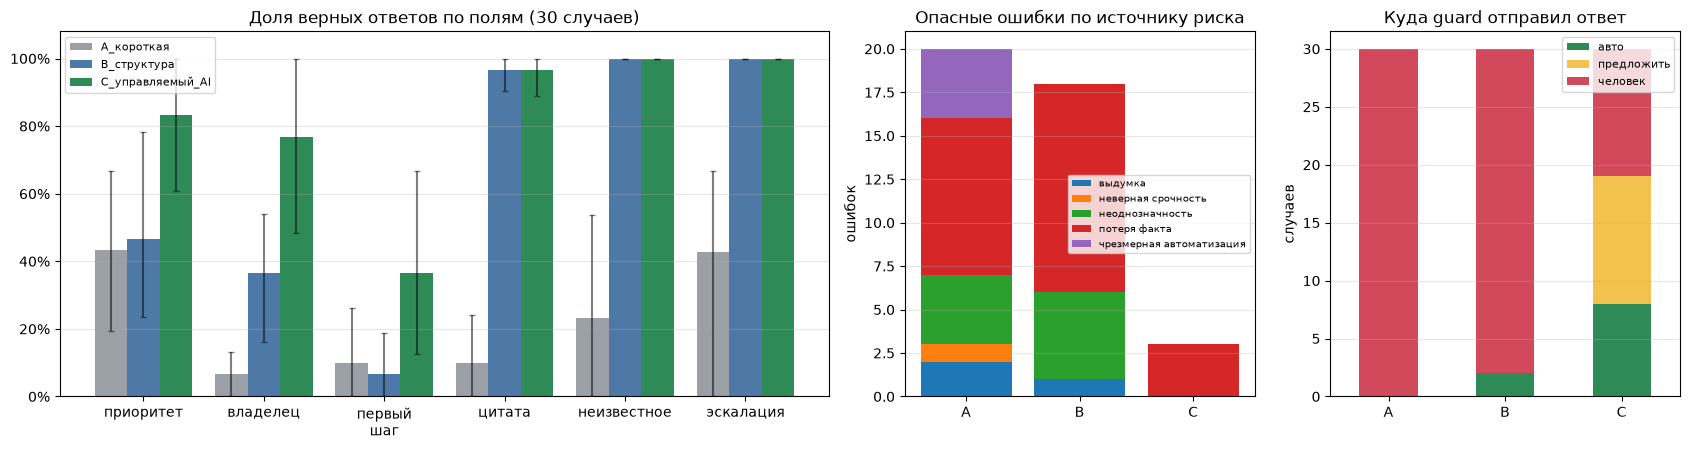

In [9]:
os.makedirs('img', exist_ok=True)
COLORS = {'A_короткая': '#9aa0a6', 'B_структура': '#4e79a7', 'C_управляемый_AI': '#2e8b57'}
SHOW = ['severity_ok', 'owner_ok', 'first_action_ok', 'evidence_ok', 'unknowns_ok', 'escalation_recall']
SHORT = ['приоритет', 'владелец', 'первый\nшаг', 'цитата', 'неизвестное', 'эскалация']

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [2.2, 1, 1]})
s = summary[summary.model == MODEL].set_index(['prompt_version', 'metric'])
x = np.arange(len(SHOW))
for i, v in enumerate(VERSIONS):
    if v not in s.index.get_level_values(0):
        continue
    vals = [s.loc[(v, m), 'value'] for m in SHOW]
    lo = [s.loc[(v, m), 'value'] - s.loc[(v, m), 'ci_lo'] for m in SHOW]
    hi = [s.loc[(v, m), 'ci_hi'] - s.loc[(v, m), 'value'] for m in SHOW]
    axes[0].bar(x + (i - 1) * .27, vals, .27, yerr=[lo, hi], capsize=2, color=COLORS[v], label=v, error_kw={'alpha': .5})
axes[0].set_xticks(x, SHORT)
axes[0].set(title='Доля верных ответов по полям (30 случаев)', ylim=(0, 1.08))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
axes[0].legend(loc='upper left', fontsize=8); axes[0].grid(alpha=.3, axis='y')

src = by_source(MODEL).drop(index='ответов с опасной ошибкой')
bottom = np.zeros(len(VERSIONS))
for name, row in src.iterrows():
    axes[1].bar(range(len(VERSIONS)), row.values, bottom=bottom, label=name)
    bottom += row.values
axes[1].set_xticks(range(len(VERSIONS)), ['A', 'B', 'C'])
axes[1].set(title='Опасные ошибки по источнику риска', ylabel='ошибок')
axes[1].legend(fontsize=7); axes[1].grid(alpha=.3, axis='y')

routes = pd.crosstab(journal.prompt_version, journal.guard_route).reindex(index=VERSIONS, columns=['авто', 'предложить', 'человек'], fill_value=0)
routes.plot.bar(stacked=True, ax=axes[2], color=['#2e8b57', '#f2c14e', '#d1495b'], rot=0)
axes[2].set_xticks(range(len(VERSIONS)), ['A', 'B', 'C'])
axes[2].set(title='Куда guard отправил ответ', xlabel='', ylabel='случаев')
axes[2].legend(fontsize=8); axes[2].grid(alpha=.3, axis='y')

plt.tight_layout()
plt.savefig('img/сравнение_версий.png', dpi=150, bbox_inches='tight')
plt.show()

**Что получилось.** Версия C лучше там, где вообще есть разница: приоритет 83% [61–100%] против 43% у A и 47% у B, владелец 77% против 7% и 37%, первый шаг 37% против 10% и 7%. Опасных ошибок у A 17 из 30, у B 14, у C 3. По опасным ошибкам C − A = −47 п.п. [−71; −24], C − B = −37 п.п. [−66; −8]: интервалы не задевают ноль, то есть это не везение выборки. А вот разница B − A (−10 п.п. [−21; 0]) ничего не доказывает. Самый частый источник риска — потеря факта: 9 у A, 12 у B, 3 у C, модель занижает критичность.

Структура (B) сама по себе дает только форму: JSON валидный в 100% ответов, цитата дословная в 97%, неизвестное отмечено всегда. Приоритет и владелец у B почти такие же, как у A, а человека B зовет в 28 случаях из 30 — безопасно, но автоматизации никакой. У C JSON валидный в 29 ответах из 30: в INC-017 модель посреди ответа перешла на китайский и выдала второй JSON на английском. У A дословная цитата есть только в 3 ответах, и все три раза это слово «срочно», неизвестное отмечено в 7 ответах из 30.

Карточка целиком верна (приоритет, владелец, первый шаг, цитата и human_review сразу) только у C, и то в 20% случаев. Обычно не дотягивает первый шаг: в эталоне он из двух частей («снизить скорость **и** проверить узел»), а модель делает одну.

In [10]:
view = journal.merge(cases[['incident_id', 'template', 'urgent']], on='incident_id')
view['текст'] = view.template + np.where(view.urgent, ' + «срочно»', '')
stab = view.groupby(['текст', 'gold_severity', 'prompt_version']).model_severity.agg(lambda s: ', '.join(s)).unstack()[VERSIONS]
stab.columns.name = None
display(stab)
st = summary[(summary.model == MODEL) & (summary.metric == 'stable_severity')].set_index('prompt_version').value[VERSIONS]
print('доля текстов, где все повторы получили одинаковую критичность:', ', '.join(f'{v}: {x:.0%}' for v, x in st.items()))

,,A_короткая,B_структура,C_управляемый_AI
текст,gold_severity,,,
T1,Критический,"Высокий, Высокий, Высокий, Высокий, Высокий","Высокий, Высокий, Высокий, Высокий, Высокий","Критический, Высокий, Критический, Высокий, Вы..."
T2,Высокий,"Средний, Средний, Критический","Средний, Средний, Высокий","Высокий, Высокий, Высокий"
T2 + «срочно»,Высокий,"Критический, Критический","Высокий, Высокий","Высокий, Высокий"
T3,Средний,"Средний, Средний, Критический, Средний, Высокий","Средний, Средний, Высокий, Высокий, Высокий","Средний, Средний, Средний, Средний, Средний"
T4,Низкий,"Низкий, Средний","Низкий, Низкий","Низкий, Низкий"
T4 + «срочно»,Низкий,"Средний, Средний, Низкий","Низкий, Низкий, Низкий","Низкий, Низкий, Низкий"
T5,Высокий,"Высокий, Высокий, Высокий, ,","Средний, Средний, Средний, Средний, Средний","Высокий, Высокий, Высокий, Высокий, Высокий"
T6,Средний,"Средний, Средний, Средний","Средний, Низкий, Средний","Средний, Средний, Средний"
T6 + «срочно»,Средний,"Средний, Средний","Средний, Средний","Высокий, Высокий"


доля текстов, где все повторы получили одинаковую критичность: A_короткая: 44%, B_структура: 67%, C_управляемый_AI: 89%


**Стабильность.** Одинаковые тексты должны получать одинаковую критичность, но у A так только для 4 текстов из 9 (44%), у B для 6 (67%), у C для 8 (89%). Хуже всего у A шаблон T3 (терминалы): на пять одинаковых сообщений модель выдала Средний, Средний, Критический, Средний, Высокий. Получается, результат зависит от seed, а не от сообщения. У C гуляет только T1 (сервис перестал отвечать после обновления): два раза Критический, три раза Высокий. Похоже, модель цепляется за «резерв пока работает» и решает, что раз резерв есть, то еще не критично.

Стабильно не значит правильно. B все пять раз ставит T5 (входы из необычной страны) Средний, а T1 — Высокий, и это опасные ошибки. У C тоже есть стабильная ошибка: оба сообщения T6 с припиской «срочно» получили Высокий вместо Среднего, хотя без приписки все три раза Средний. Правило «срочно не повышает критичность» в C написано, но модель выполняет его не всегда. Тут страхует guard: такие сообщения он всегда отправляет человеку.

## Шаг 5. Пять опасных ошибок

Ниже все ответы, где сработало хотя бы одно правило опасной ошибки (уже с ручной проверкой). Из них выбрал пять с разными источниками риска и разобрал подробно.

In [11]:
cols = ['incident_id', 'prompt_version', 'model_severity', 'gold_severity', 'model_owner', 'model_first_action',
        'model_human_review', 'gold_human_review', 'error_source', 'guard_route', 'comment']
dangerous = journal[journal.dangerous_error == 'да']
print('ответов с опасной ошибкой:', dangerous.prompt_version.value_counts().reindex(VERSIONS, fill_value=0).to_dict())
display(dangerous[cols].sort_values(['prompt_version', 'incident_id']))

ответов с опасной ошибкой: {'A_короткая': 17, 'B_структура': 14, 'C_управляемый_AI': 3}


,incident_id,prompt_version,model_severity,gold_severity,model_owner,model_first_action,model_human_review,gold_human_review,error_source,guard_route,comment
0,INC-001,A_короткая,Высокий,Критический,,Приоритетное устранение неполадок: Немедленно ...,нет,нет,потеря факта,человек,занижен приоритет: Высокий вместо Критический;...
3,INC-002,A_короткая,Средний,Высокий,,Обратите внимание на оборудование: Наблюдайте ...,нет,нет,потеря факта,человек,занижен приоритет: Средний вместо Высокий; вла...
12,INC-005,A_короткая,Высокий,Высокий,,Проведение дополнительной проверки: Увеличьте ...,нет,нет,выдумка; неоднозначность,человек,владелец не назван; первый шаг не тот; нет цит...
18,INC-007,A_короткая,Высокий,Критический,техподдержка,Информирование управления: Срочно уведомите ру...,нет,нет,потеря факта,человек,занижен приоритет: Высокий вместо Критический;...
21,INC-008,A_короткая,Критический,Высокий,,Проведение диагностики:; Остановить производст...,нет,да,чрезмерная автоматизация,человек,приоритет Критический вместо Высокий; владелец...
30,INC-011,A_короткая,Высокий,Высокий,,Имmediately investigate the unusual activity: ...,нет,нет,неоднозначность,человек,владелец не назван; первый шаг только частично...
36,INC-013,A_короткая,Высокий,Критический,,"Подтвердите статус системы: Проверьте, действи...",нет,нет,потеря факта,человек,занижен приоритет: Высокий вместо Критический;...
39,INC-014,A_короткая,Средний,Высокий,инженер,Проведите ближайший осмотр оборудования и сбор...,нет,нет,потеря факта,человек,занижен приоритет: Средний вместо Высокий; вла...
42,INC-015,A_короткая,Критический,Средний,поставщики и внутренние службы IT,"Идентификация проблем:; Определите, какие имен...",нет,нет,неверная срочность,человек,завышен приоритет: Критический вместо Средний;...
45,INC-016,A_короткая,Средний,Низкий,,Информирование пользователя: Ответьте пользова...,нет,да,чрезмерная автоматизация,человек,приоритет Средний вместо Низкий; владелец не н...


**Разбор пяти ошибок.** Взял по одной на каждый источник риска. Ответы целиком — в `КТ2_ответы_модели.md`.

1. **Потеря факта — INC-007, версия C.** Модель поставила Высокий, хотя сама же выписала цитату «затронуты корпоративные клиенты». Эталон — Критический: основной сервис не отвечает, и это уже касается клиентов. Видимо, перевесило «резерв пока работает». *Чем опасно:* критический инцидент встает в очередь как высокий, не срабатывает правило «критический не подтвержден за 5 минут — звонок дежурному», клиенты ждут дольше. Так выглядят все три оставшиеся ошибки C (INC-007, 019, 025). *Что закрывает:* guard отправил их в «предложить», диспетчер видит карточку до любых действий. Но в симуляции он пропускает такую ошибку 0,5–1 раз за смену, поэтому нужно правило в guard («не отвечает» + «клиенты» → не ниже Критического) и пример в C.
2. **Неоднозначность — INC-002, версия B.** Вибрация и температура подшипника пришли из канала «ИТ», и модель отдала их «Отделу технической поддержки» со средним приоритетом. Эталон — начальник смены, Высокий, снизить скорость линии. *Чем опасно:* ИТ ничего не сделает с подшипником, а линия продолжает работать с растущей вибрацией — до поломки или аварии. *Что закрывает:* в C есть правило «Отрасль — это только канал» и справочник владельцев, все пять T2 у C ушли начальнику смены. Guard тоже ловит: «вибрация», «температура» при приоритете ниже высокого — сразу к человеку.
3. **Выдумка — INC-005, версия A.** В сообщении только «входы из необычной страны и серия неуспешных попыток». Модель придумала транзакции и мошенничество: первым шагом «увеличьте уровень проверки транзакций», вторым — сообщить финансовым регуляторам и в полицию. Эталон — служба ИБ, изолировать учетную запись. *Чем опасно:* диспетчер запускает антифрод и выносит наружу «мошенничество», которого нет, а учетная запись остается открытой. *Что закрывает:* запрет на выдумывание и дословная цитата в C, guard сверяет цитату с текстом. У C все пять T5 ушли в ИБ без лишних фактов.
4. **Неверная срочность — INC-015, версия A.** «Часть терминалов не синхронизирует остатки» — уровня модель не дала, но трижды написала «это критично» (финансово, операционно, технологически). По смыслу это Критический при эталонном Среднем. *Чем опасно:* ложная тревога отвлекает дежурных от настоящих аварий, а после пары таких тревог карточкам перестают верить. *Что закрывает:* в C критичность считается по влиянию и масштабу, все пять T3 у C — Средний.
5. **Чрезмерная автоматизация — INC-024, версия A.** «Срочно», а число затронутых не указано. Модель сама пишет «несмотря на то что точное количество затронутых объектов не указано, важно быстро принять меры» и первым шагом предлагает немедленно уведомить всех клиентов. Эталон — сначала человек выясняет масштаб. *Чем опасно:* массовое действие из-за одного «срочно» без фактов. *Что закрывает:* обязательная эскалация в C (у C во всех 7 таких случаях human_review = да) и правило guard «автор давит срочностью — к человеку», которое работает, даже если модель ошиблась.

Отдельно про сбои у A: INC-020 и INC-029 посреди ответа переходят на китайский (в INC-020 — текст про экологию и госорганы), а INC-029 вообще не дает ни критичности, ни действия. Без guard такой ответ мог бы уйти исполнителю как есть.

## Шаг 6. Режим работы

Главная мысль, к которой я пришел: решать, что можно автоматизировать, должна не сама модель, а простые проверяемые правила после нее. Модель может уверенно ошибиться, а правило «в тексте есть слово вибрация, а приоритет средний» не ошибется никогда. Эти правила я назвал guard, он написан на Rust (`rust/src/guard.rs`) и эталона не видит, только сообщение и ответ модели.

| что | кто | когда |
|---|---|---|
| разобрать сообщение в карточку: факты, цитата, неизвестное, предложения | AI автоматически | всегда |
| проверить карточку: формат, цитата есть в тексте, нет давления «срочно», нет слов опасности при низком приоритете | guard автоматически | всегда, за доли миллисекунды |
| отправить владельцу случай Низкий/Средний | AI автоматически, диспетчер видит ленту и может вернуть | guard не нашел ни одной причины звать человека |
| критичность Высокий/Критический, владелец, первый шаг | AI только **предлагает**, диспетчер подтверждает одной кнопкой | severity ≥ Высокий или шаг меняет работу системы (остановить, изолировать, откатить, снизить скорость) |
| решение целиком | **человек**, AI дает только черновик | нет структуры; цитаты нет в тексте; модель сама просит человека; «срочно» без масштаба; слова опасности при низком приоритете |

Правила эскалации и безопасности:
1. AI никогда сам не делает действий, которые меняют работу систем и людей: остановить линию, заблокировать учетку, откатить релиз. Только предлагает.
2. Критический не подтвержден за 5 минут — автоматический звонок дежурному и старшему смены. Это уведомление, а не действие.
3. «Срочно» от автора само по себе ничего не повышает, но и не игнорируется: такой случай всегда уходит к человеку с вопросом «какой масштаб?».
4. Похожие сообщения подряд (в данных 30 сообщений — это всего 6 разных ситуаций) AI склеивает в один инцидент, но склейку показывает диспетчеру.
5. Каждое исправление диспетчером критичности или владельца пишется в лог. Раз в неделю разбор и правка инструкции C. Ответы в «авто» раз в смену выборочно проверяет старший.
6. Данные инцидентов (особенно ИБ) не уходят во внешние сервисы: модель локальная.

Что мерить на пилоте: опасных ошибок, прошедших в «авто» (цель — 0); доля карточек, где диспетчер исправил критичность или владельца; время от сообщения до первого действия по критическим; доли «авто» / «предложить» / «человек».

Проверяю guard на тех же 90 ответах: куда он отправил бы каждый ответ и сколько опасных ошибок проскочило бы без человека.

In [12]:
guard_view = pd.crosstab([journal.prompt_version, journal.guard_route], journal.dangerous_error).reindex(columns=['нет', 'да'], fill_value=0)
guard_view.columns = ['без опасной ошибки', 'с опасной ошибкой']
display(guard_view)
leak = journal[(journal.dangerous_error == 'да') & (journal.guard_route == 'авто')]
print('опасных ошибок, которые guard пропустил бы без человека:', len(leak))
print('\nпочему guard отправил к человеку (версия C):')
print(journal[(journal.prompt_version == 'C_управляемый_AI') & (journal.guard_route == 'человек')].guard_reason.str.split('; ').explode().value_counts().to_string())

без опасной ошибки  с опасной ошибкой
prompt_version   guard_route                                       
A_короткая       человек                      13                 17
B_структура      авто                          2                  0
                 человек                      14                 14
C_управляемый_AI авто                          8                  0
                 предложить                    8                  3
                 человек                      11                  0

опасных ошибок, которые guard пропустил бы без человека: 0

почему guard отправил к человеку (версия C):
guard_reason
модель просит человека        9
автор давит срочностью        7
цитата не найдена в тексте    1
нет структуры                 1


**Guard.** В «авто» не ушла ни одна опасная ошибка. У A структуры нет, и guard все 30 ответов отправил человеку. У B все 14 опасных ошибок тоже у человека, но туда же попали 28 ответов из 30, потому что B сама почти всегда просит проверку. У C три опасные ошибки (T1, Высокий вместо Критического) попали в «предложить»: диспетчер их видит, но должен сам заметить ошибку. На этих случаях безопасность держится на его внимании.

У C guard распределил ответы так: 8 (27%) в «авто», 11 (37%) в «предложить», 11 (37%) к человеку. К человеку чаще всего по двум причинам: модель сама попросила (9 раз) и автор давит срочностью (7 раз, это все сообщения со «срочно»). Еще по разу — пересказ вместо цитаты (INC-014) и сломанный JSON (INC-017).

В «авто» опасных ошибок нет, но и чисто там не все. Все пять сообщений про терминалы (T3) ушли в «авто», и ни в одном нет эталонного владельца: C отдает их сервис-менеджеру или дежурному инженеру, а не руководителю склада. Ошибка неопасная, приоритет средний, но в автоматическом режиме карточка уйдет не тем людям. Это надо поправить в C примером про склад, а на пилоте ловить выборочной проверкой «авто».

### Экономия времени

Считаю в два шага.

**1. Простая формула на одно сообщение.** Без AI диспетчер тратит `t_ручной` на чтение и карточку. С AI время зависит от того, куда guard отправил ответ:

`t_AI = доля_авто · t_просмотр + доля_предложить · t_подтвердить + доля_человек · (t_ручной + t_черновик)`

Доли маршрутов беру из эксперимента (версия C на 30 случаях), времена — из допущений в `data/допущения_времени.csv` (по каждому есть минимум, типичное и максимум). Реальных замеров времени у меня нет, это первое, что надо снять на пилоте.

**2. Симуляция смены на Rust.** Формула не показывает главное: критический инцидент не ждет в очереди за мелочами. Поэтому моделирую смену (8 часов) как очередь:
- сообщения приходят случайно (пуассоновский поток, 6 / 9 / 12 в час);
- у каждого сообщения берется случайный реальный исход версии C из эксперимента: настоящая критичность, что сказала модель, куда отправил guard, была ли ошибка;
- вручную диспетчер разбирает по порядку прихода; с AI — сначала то, что модель пометила как более критичное, плюс модель думает столько, сколько реально думала в прогоне (на видеокарте около секунды на ответ C);
- ошибку AI человек замечает с вероятностью 80–97% при подтверждении и 95–100% при полном разборе, исправление стоит 1–4 минуты, в «авто» ошибку никто не ловит;
- на каждый сценарий 100 тыс. смен, режимы сравниваю на одном и том же потоке сообщений.

In [13]:
assume = pd.read_csv(DATA / 'допущения_времени.csv')
display(assume)

c_routes = journal[journal.prompt_version == 'C_управляемый_AI'].guard_route.value_counts(normalize=True).reindex(['авто', 'предложить', 'человек'], fill_value=0)
t = assume.set_index('param')['mode']
manual = t.t_manual
with_ai = c_routes['авто'] * t.t_auto + c_routes['предложить'] * t.t_suggest + c_routes['человек'] * (t.t_manual + t.t_human_extra)
print('доли маршрутов C:', ', '.join(f'{k} {v:.0%}' for k, v in c_routes.items()))
print(f'вручную: {manual:.1f} мин на сообщение, с AI: {with_ai:.2f} мин → экономия {manual - with_ai:.2f} мин ({1 - with_ai / manual:.0%})')
for per_hour in [6, 9, 12]:
    per_month = per_hour * 8 * t.shifts_per_month
    print(f'  {per_hour} сообщений в час: {per_month:,.0f} сообщений в месяц → экономия {(manual - with_ai) * per_month / 60:,.0f} ч в месяц'.replace(',', ' '))

,param,min,mode,max,comment
0,t_manual,3.00,5.00,8.00,диспетчер сам читает сообщение и заполняет кар...
1,t_auto,0.30,0.50,1.00,беглый просмотр карточки которую guard пропуст...
2,t_suggest,0.50,1.00,2.00,проверить и подтвердить предложение AI (мин)
3,t_human_extra,0.30,0.50,1.00,прочитать черновик AI сверх ручного разбора (мин)
4,t_fix,1.00,2.00,4.00,исправить ошибку AI которую человек заметил (мин)
5,p_catch_suggest,0.80,0.90,0.97,шанс что человек заметит ошибку при подтверждении
6,p_catch_human,0.95,0.98,1.00,шанс что человек заметит ошибку при полном раз...
7,lambda_per_hour,6.00,9.00,12.00,три сценария потока сообщений в час
8,shift_min,480.00,480.00,480.00,длина смены (мин)
9,shifts_per_month,90.00,90.00,90.00,смен в месяц при работе 24/7


доли маршрутов C: авто 27%, предложить 37%, человек 37%
вручную: 5.0 мин на сообщение, с AI: 2.52 мин → экономия 2.48 мин (50%)
  6 сообщений в час: 4 320 сообщений в месяц → экономия 179 ч в месяц
  9 сообщений в час: 6 480 сообщений в месяц → экономия 268 ч в месяц
  12 сообщений в час: 8 640 сообщений в месяц → экономия 358 ч в месяц


,lambda_per_hour,mode,messages_per_shift,busy_min,загрузка,overtime_min,crit_first_action_p50,crit_first_action_p90,позже_15_мин,uncaught_dangerous_per_shift,saved_min_p10,saved_min_p50,saved_min_p90,saved_hours_month_p50
0,6.0,вручную,48.00,256.04,53%,3.16,6.76,14.61,9%,NaN,NaN,NaN,NaN,NaN
1,6.0,AI + guard,48.00,153.48,32%,1.35,3.13,6.84,0%,0.53,70.28,101.92,135.73,152.87
2,9.0,вручную,71.97,383.90,80%,10.95,11.42,29.72,37%,NaN,NaN,NaN,NaN,NaN
3,9.0,AI + guard,71.97,230.25,48%,2.64,3.48,8.39,1%,0.79,113.97,153.18,194.04,229.77
4,12.0,вручную,96.03,512.23,107%,59.72,33.66,85.79,78%,NaN,NaN,NaN,NaN,NaN
5,12.0,AI + guard,96.03,307.07,64%,5.09,3.95,9.87,2%,1.05,159.38,204.56,251.73,306.84


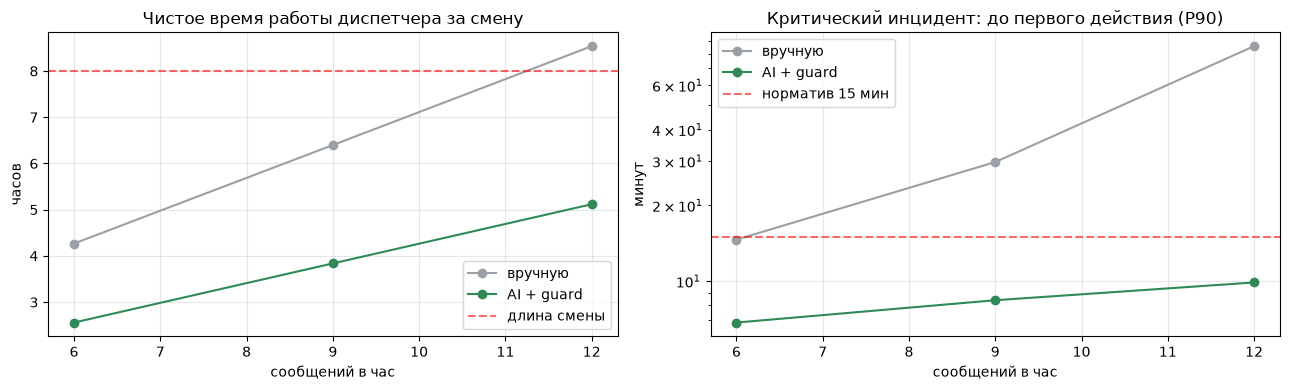

In [14]:
sim = pd.read_csv(DATA / 'rust_sim.csv')
show = sim.assign(загрузка=sim.utilization.map('{:.0%}'.format), позже_15_мин=sim.crit_late_share.map('{:.0%}'.format))
display(show[['lambda_per_hour', 'mode', 'messages_per_shift', 'busy_min', 'загрузка', 'overtime_min',
              'crit_first_action_p50', 'crit_first_action_p90', 'позже_15_мин', 'uncaught_dangerous_per_shift',
              'saved_min_p10', 'saved_min_p50', 'saved_min_p90', 'saved_hours_month_p50']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mode, color in [('вручную', '#9aa0a6'), ('AI + guard', '#2e8b57')]:
    d = sim[sim['mode'] == mode]
    axes[0].plot(d.lambda_per_hour, d.busy_min / 60, 'o-', color=color, label=mode)
    axes[1].plot(d.lambda_per_hour, d.crit_first_action_p90, 'o-', color=color, label=mode)
axes[0].axhline(8, color='red', ls='--', alpha=.6, label='длина смены')
axes[0].set(title='Чистое время работы диспетчера за смену', xlabel='сообщений в час', ylabel='часов')
axes[1].axhline(15, color='red', ls='--', alpha=.6, label='норматив 15 мин')
axes[1].set(title='Критический инцидент: до первого действия (P90)', xlabel='сообщений в час', ylabel='минут')
axes[1].set_yscale('log')
for ax in axes:
    ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig('img/экономия_времени.png', dpi=150, bbox_inches='tight')
plt.show()

**Экономия.** По формуле с долями маршрутов C (27% «авто», 37% «предложить», 37% «человек») диспетчер тратит 2,5 минуты на сообщение вместо 5, экономия 2,5 минуты, или 50%. При 6, 9 и 12 сообщениях в час это 179, 268 и 358 часов в месяц при работе 24/7.

Симуляция дает чуть меньше, потому что учитывает разброс времени и исправление ошибок AI. Медиана экономии — 102 минуты за смену при 6 сообщениях в час (P10–P90: 70–136), 153 при 9 (114–194) и 205 при 12 (159–252). В месяц это 153, 230 и 307 часов, примерно одна-две ставки диспетчера.

Но главное тут не минуты. При 12 сообщениях в час диспетчер без AI загружен на 107%: очередь растет всю смену, и в среднем он перерабатывает час. Критический инцидент в 10% случаев ждет первого действия дольше 86 минут, норматив 15 минут нарушается в 78% случаев. Уже при 9 сообщениях в час вручную норматив нарушается в 37% случаев (P90 — 30 минут). С AI критические идут в начало очереди, и P90 держится в пределах 7–10 минут при любом потоке, позже норматива — не больше 2%.

Цена — ошибки, которые никто не заметил: в симуляции за смену проходит 0,5–1 опасная ошибка. Это те самые T1, где C поставила Высокий вместо Критического, а диспетчер подтвердил не глядя (в модели он замечает ошибку в 80–97% случаев). Ручной режим я считал безошибочным, это ему в плюс. Все времена — допущения, их первыми надо замерить на пилоте.

## Проверка на второй модели

Чтобы понять, что разница между версиями — это эффект инструкции, а не особенность одной модели, прогнал те же 90 запросов на llama3 (8B) — модель другого разработчика, но того же размера. Оценка та же: Rust, рубрика, guard. Ручную проверку для llama3 не делал, поэтому цифры по ней чуть грубее.

In [15]:
if (summary.model == SECOND).any():
    display(metric_table(SECOND))
    display(by_source(SECOND))
else:
    print(f'ответов {SECOND} нет в кэше')

,A_короткая,B_структура,C_управляемый_AI
формат: валидный JSON,0% [0%–0%],90% [72%–100%],53% [40%–65%]
приоритет,33% [6%–65%],47% [21%–67%],70% [40%–91%]
владелец,3% [0%–12%],10% [0%–21%],73% [42%–100%]
первый шаг,17% [0%–34%],0% [0%–0%],17% [4%–29%]
цитата дословно,23% [5%–56%],43% [19%–72%],100% [100%–100%]
неизвестное отмечено,20% [5%–44%],77% [44%–100%],57% [47%–68%]
human_review как в эталоне,77% [48%–95%],17% [3%–36%],77% [60%–94%]
"эскалация там, где нужна (7 сл.)",14% [0%–50%],57% [33%–100%],71% [50%–100%]
карточка целиком верна,0% [0%–0%],0% [0%–0%],3% [0%–11%]
опасные ошибки,50% [24%–79%],80% [62%–95%],10% [0%–28%]


,A_короткая,B_структура,C_управляемый_AI
metric,,,
выдумка,0,15,0
неверная срочность,7,1,2
неоднозначность,0,9,0
потеря факта,6,3,0
чрезмерная автоматизация,6,3,2
ответов с опасной ошибкой,15,24,3


**llama3.** По опасным ошибкам C и тут лучшая: 3 из 30 против 15 у A и 24 у B. По приоритету и владельцу тоже C (70% и 73%). Значит, главный эффект дают правила, справочник и примеры в C, а не особенность qwen.

Но порядок A < B < C на llama3 не повторился: B у нее хуже A. Больше всего у B выдумок (15). llama3 в 26 ответах из 30 начинает с «Here is…», а в 13 переводит цитату на английский, и дословно в тексте ее уже не найти. Есть и настоящие выдумки: в INC-022 «цитата» — «Отчёт не открывается в течение 10 минут», хотя никаких минут в сообщении нет, в INC-005 первый шаг — «block suspicious transactions». Еще 9 раз неоднозначность: владельцы вроде Financial Risk Management, Telecom Operations, Network Operations Center модель берет из поля отрасли. Получается, структура без справочника и запрета на выдумывание может сделать хуже: поле обязательное, и модель заполняет его чем угодно.

У C на llama3 своя проблема — формат. Валидный JSON только в 16 ответах из 30, в остальных 14 нет закрывающей скобки. Guard отправил их к человеку, поэтому в «авто» ушло всего 4 ответа, и экономии почти нет. Для работы оставляю qwen2.5:7b, а проверку формата в guard считаю обязательной при любой модели.

## Решение о пилоте

> На 30 случаях версия C дала 3 опасные ошибки против 17 у A и 14 у B (C − A: −47 п.п. [−71; −24]), guard не пропустил в «авто» ни одной, все три ушли диспетчеру на подтверждение. Рекомендуется **revise**, потому что все три оставшиеся ошибки одного типа (сервис перестал отвечать, клиенты затронуты, а модель ставит Высокий вместо Критического), и в симуляции диспетчер пропускает такую ошибку 0,5–1 раз за смену. Еще в «авто» уходят карточки про склад с неверным владельцем.

Что сделать до go:
1. закрыть T1: добавить в C пример «основной сервис не отвечает, резерв работает, клиенты затронуты → Критический» и правило в guard: «не отвечает / недоступен» вместе с «клиенты» → не ниже Критического, иначе к человеку;
2. добавить в C пример про склад, а в guard — проверку, что владелец есть в справочнике (сейчас прошел «서비스-менеджер» с корейскими буквами);
3. проверить на новых сообщениях: 30 случаев — это всего 9 разных текстов, интервалы широкие;
4. пилот на 2–4 недели в режиме «AI предлагает, человек подтверждает». «Авто» включать только для Низкий/Средний и только после недели без ошибок в выборочной проверке. Контроль: опасных ошибок в «авто» — 0, доля карточек, где диспетчер исправил критичность или владельца, время до первого действия по критическим (цель — 15 минут), реальные замеры t_manual и t_suggest вместо допущений.